<a href="https://colab.research.google.com/github/OJB-Quantum/MuMax3-How-To/blob/main/MuMax%20Notebooks/Hysteresis_Loop_and_Magnetization_Permalloy_MuMaxPlus.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Authored by Onri Jay Benally (2026)

Open Access (CC-BY-4.0)

In [ ]:
!uv pip install mumaxplus matplotlib numpy

Estimated Hc: 17.44 kA/m (21.91 mT)
Estimated Mr: 7.732e+05 A/m (mx = 0.9665)


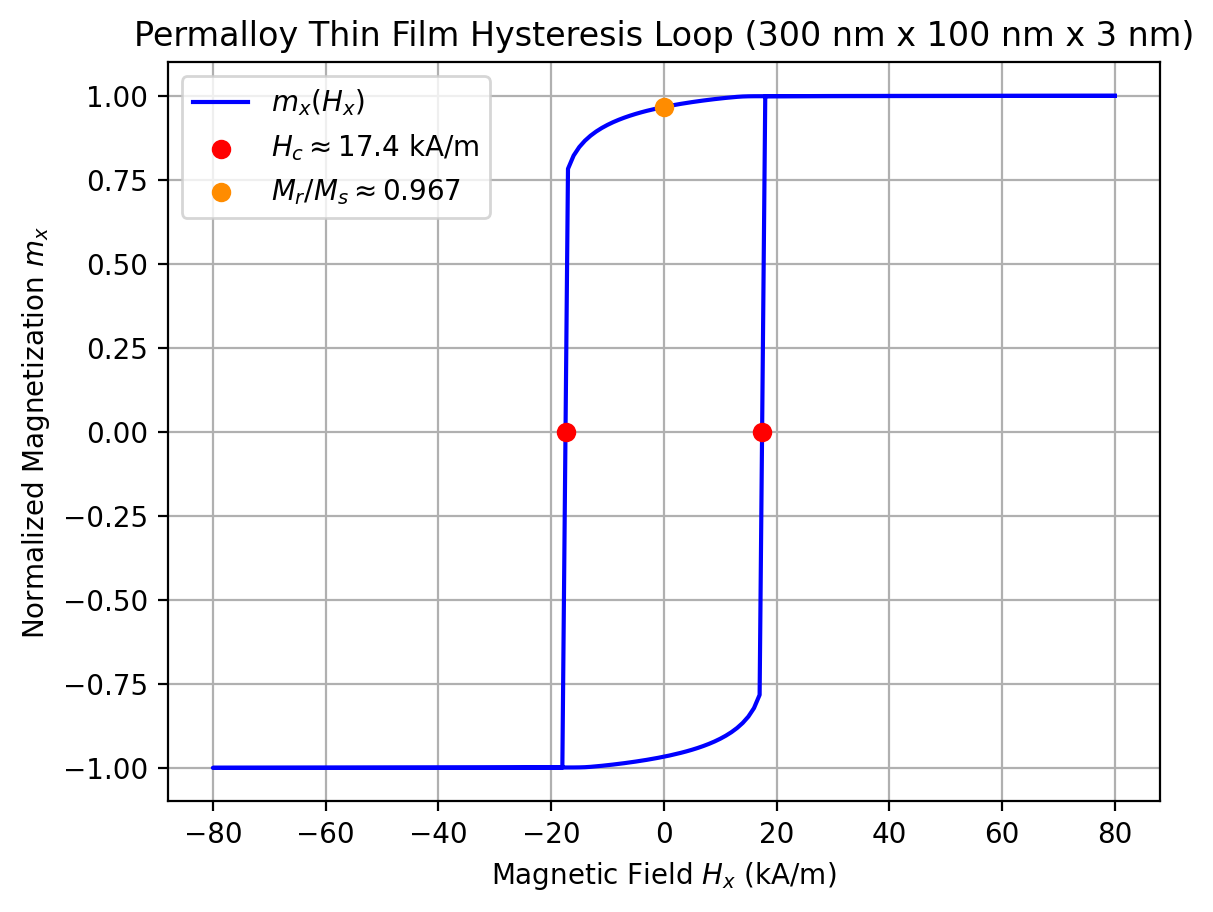

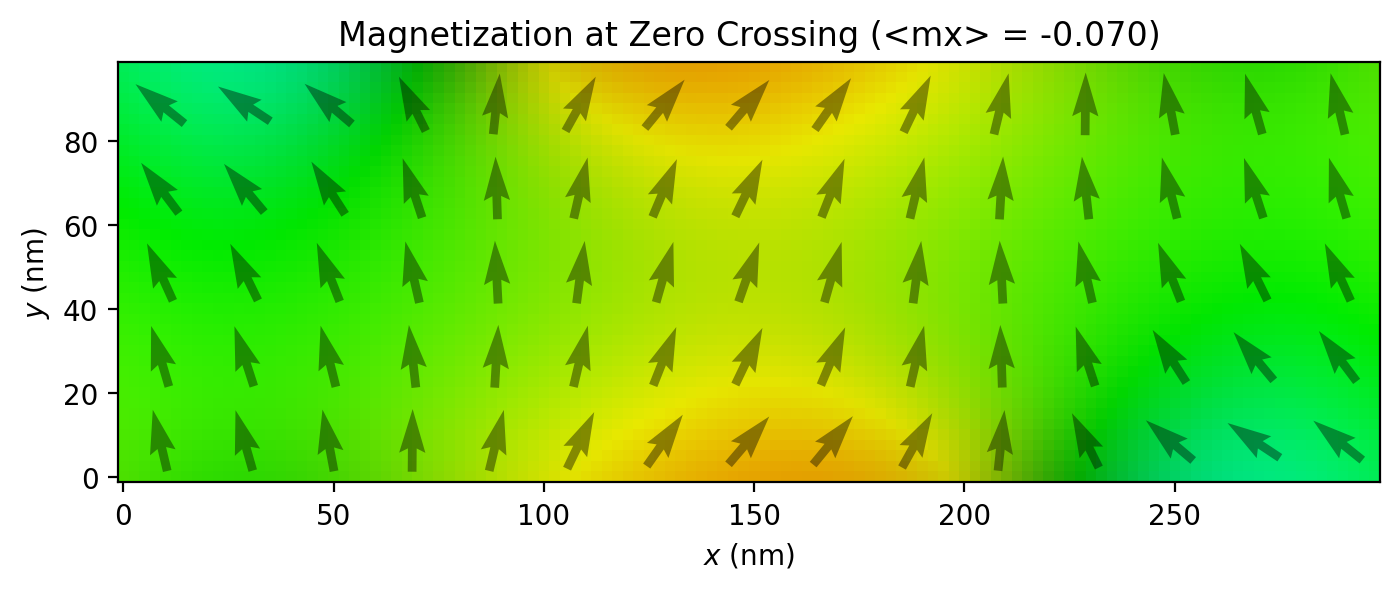

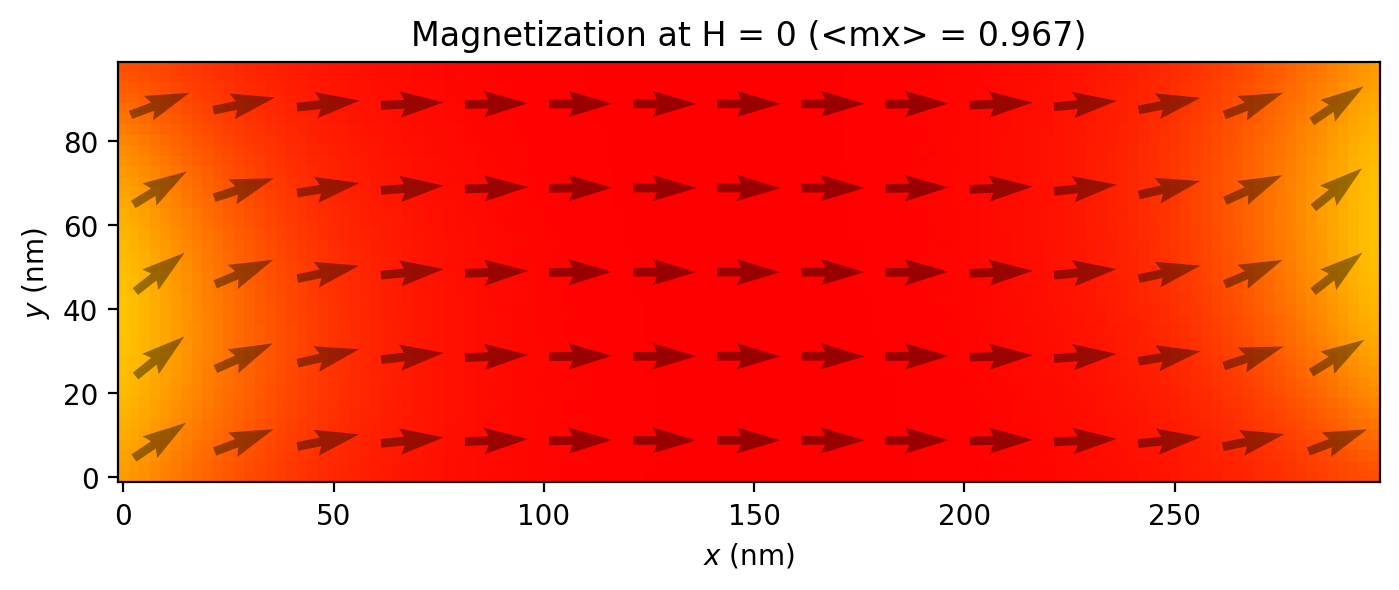

In [3]:
"""This script solves the Permalloy thin-film hysteresis problem in mumaxplus.

The simulation computes the longitudinal hysteresis loop, estimates coercivity
and remanent magnetization, and renders magnetization snapshots at remanence
and across the zero-magnetization crossing on a GPU in Google Colab.
"""

import matplotlib.pyplot as plt
from mumaxplus import Ferromagnet
from mumaxplus import Grid
from mumaxplus import World
from mumaxplus.util import plot_field
import numpy as np

plt.rcParams['figure.dpi'] = 200

mu0 = 4.0 * np.pi * 1e-7
msat = 8.0e5
world = World(cellsize=(2.5e-9, 2.5e-9, 3.0e-9))
magnet = Ferromagnet(world, Grid((120, 40, 1)))

magnet.msat = msat
magnet.aex = 1.3e-11
magnet.ku1 = 0.0
magnet.alpha = 0.02
magnet.magnetization = (1.0, 0.0, 0.0)

h_max = 80e3
h_step = 1e3
h_down = np.arange(h_max, -h_max - h_step * 0.5, -h_step)
h_up = np.arange(-h_max + h_step, h_max + h_step * 0.5, h_step)
h_array = np.concatenate((h_down, h_up))

mx_list = []
m_rem = None
m_pre_switch = None
h_switch = None
crossed = False
mr_norm = 0.0
hc_est = 0.0

world.bias_magnetic_field = (mu0 * h_max, 1e-4, 0.0)
magnet.minimize()

for idx, h_ext in enumerate(h_array):
    prev_state = magnet.magnetization.eval()
    world.bias_magnetic_field = (mu0 * h_ext, 1e-4, 0.0)
    magnet.minimize()
    mx_val = float(magnet.magnetization.average()[0])
    mx_list.append(mx_val)
    if idx < len(h_down) and np.isclose(h_ext, 0.0):
        m_rem = magnet.magnetization.eval()
        mr_norm = mx_val
    if idx < len(h_down) and not crossed and mx_val <= 0.0:
        crossed = True
        m_pre_switch = prev_state
        h_switch = h_ext
        h_prev = h_array[idx - 1]
        mx_prev = mx_list[idx - 1]
        hc_est = abs(
            h_prev + (0.0 - mx_prev) * (h_ext - h_prev) / (mx_val - mx_prev)
        )

mr_val = mr_norm * msat
print(f'Estimated Hc: {hc_est / 1e3:.2f} kA/m ({mu0 * hc_est * 1e3:.2f} mT)')
print(f'Estimated Mr: {mr_val:.3e} A/m (mx = {mr_norm:.4f})')

magnet.magnetization = m_pre_switch
world.bias_magnetic_field = (mu0 * h_switch, 1e-4, 0.0)
for _ in range(1000):
    world.timesolver.run(1e-11)
    if magnet.magnetization.average()[0] <= 0.0:
        break
m_zero = magnet.magnetization.eval()

h_ka = h_array / 1e3
plt.plot(h_ka, mx_list, color='blue', linewidth=1.5, label='$m_x(H_x)$')
plt.scatter(
    [-hc_est / 1e3, hc_est / 1e3],
    [0.0, 0.0],
    color='red',
    zorder=5,
    label=f'$H_c \\approx {hc_est / 1e3:.1f}$ kA/m',
)
plt.scatter(
    [0.0],
    [mr_norm],
    color='darkorange',
    zorder=5,
    label=f'$M_r / M_s \\approx {mr_norm:.3f}$',
)
plt.xlabel('Magnetic Field $H_x$ (kA/m)')
plt.ylabel('Normalized Magnetization $m_x$')
plt.title('Permalloy Thin Film Hysteresis Loop (300 nm x 100 nm x 3 nm)')
plt.grid(True)
plt.legend()
plt.show()

magnet.magnetization = m_zero
mx_zero = float(magnet.magnetization.average()[0])
plot_field(
    magnet.magnetization,
    title=f'Magnetization at Zero Crossing (<mx> = {mx_zero:.3f})',
)
plt.show()

magnet.magnetization = m_rem
plot_field(
    magnet.magnetization,
    title=f'Magnetization at H = 0 (<mx> = {mr_norm:.3f})',
)
plt.show()